# 04 — EMT-TF Expression · Griffiths et al. 2021 (Breast Cancer)

Unconditional final notebook (numbered 04: Gate 3 = NA, so 04_correlation / 05_modules are not produced).
Score a wide EMT-TF panel — Snail/Zeb/Twist **plus** the FOXC and PRRX families (VIM is a mesenchymal marker,
not a TF, and is excluded) — gated on detectable expression, and overlay the thresholded expressers as a
**categorical** overlay on a grey manifold. Whether the overlay is labelled directionally (early/late) or by
expression rank depends on a test: EMT-TFs are only labelled early/late if they actually resolve along
pseudotime; here they do not, so the labels are non-directional.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 108849 | pseudotime range 0.0 -> 11.13


### Score the EMT-TF panel; select the expressers to overlay
For each TF present: fraction expressing, mean expression in the early/late pseudotime terciles, and Spearman
vs pseudotime. Restrict to detectably expressed factors (frac > 0.03). We then check whether any expressed TF
resolves along pseudotime; if the |rho| are all negligible, there is **no early/late axis** to read and the
overlay is labelled by expression rank (not direction) to avoid asserting a gradient that isn't there.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho, p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
max_abs_rho = float(ok['rho_vs_t'].abs().max())
RESOLVES = max_abs_rho >= 0.15    # threshold for a real pseudotime gradient
print('\nexpressed (frac>0.03):', ok['TF'].tolist(), '| max |rho vs pseudotime| = %.3f' % max_abs_rho)
if RESOLVES:
    tf_a = ok.sort_values('rho_vs_t').iloc[0]['TF']; tf_b = ok.sort_values('rho_vs_t').iloc[-1]['TF']
    lab_a, lab_b = f'{tf_a} (early)', f'{tf_b} (late)'
    print('directional pair: %s (early/root) <-> %s (late/terminus)' % (tf_a, tf_b))
else:
    top2 = ok.sort_values('frac_expr', ascending=False)['TF'].tolist()[:2]
    tf_a, tf_b = top2[0], top2[1]; lab_a, lab_b = tf_a, tf_b
    print('EMT-TFs do not resolve along pseudotime (all |rho| < 0.15, essentially flat) -> no early/late axis;')
    print('overlay the two most-expressed factors by expression rank (non-directional): %s, %s' % (tf_a, tf_b))

    TF  frac_expr  mean_early  mean_late  rho_vs_t
  ZEB1      0.089       0.070      0.051    -0.042
 PRRX1      0.045       0.037      0.025    -0.037
  ZEB2      0.051       0.041      0.031    -0.029
 PRRX2      0.016       0.012      0.008    -0.027
TWIST2      0.008       0.005      0.003    -0.018
 FOXC1      0.006       0.004      0.003    -0.015
TWIST1      0.017       0.010      0.009    -0.010
 SNAI2      0.003       0.003      0.002    -0.010
 SNAI1      0.002       0.001      0.001    -0.007

expressed (frac>0.03): ['ZEB1', 'PRRX1', 'ZEB2'] | max |rho vs pseudotime| = 0.042
EMT-TFs do not resolve along pseudotime (all |rho| < 0.15, essentially flat) -> no early/late axis;
overlay the two most-expressed factors by expression rank (non-directional): ZEB1, ZEB2


### `expression.pdf` — categorical overlay of thresholded expressers
Grey manifold; each of the two selected TFs overlaid as the cells above the upper-quartile of its non-zero
expression (display cutoff set, not a continuous colormap). Labels reflect the resolution test above.

overlay thresholds (upper quartile among expressers): {'ZEB1': 0.919, 'ZEB2': 0.909} | cells shown: {'ZEB1': 2429, 'ZEB2': 1395}
ZEB1: 8.9% expressing; 2429 shown (upper quartile), mean pseudotime of shown = 0.53 (all = 0.59)
ZEB2: 5.1% expressing; 1395 shown (upper quartile), mean pseudotime of shown = 0.52 (all = 0.59)
saved expression.pdf


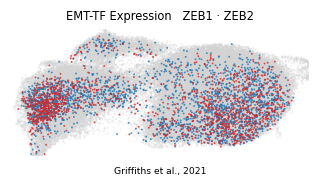

In [5]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_a, tf_b]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_a, tf_b]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf_a, tf_b]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf_a, tf_b]})
order = sorted([tf_a, tf_b], key=lambda g: -int(sel[g].sum()))
colors = {tf_a:'tab:blue', tf_b:'tab:red'}
labels = {tf_a:lab_a, tf_b:lab_b}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=6, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {labels[tf_a]} · {labels[tf_b]}', size=7.5)
ax.text(.5, -.14, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [tf_a, tf_b]:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime of shown = %.2f (all = %.2f)'
          % (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean()))
print('saved expression.pdf')